In [1]:
import xarray as xr
ds = xr.open_dataset("gebco_2026_n7.0_s2.0_w3.0_e9.0.nc")
print(ds["elevation"].values.min())

-4389.0


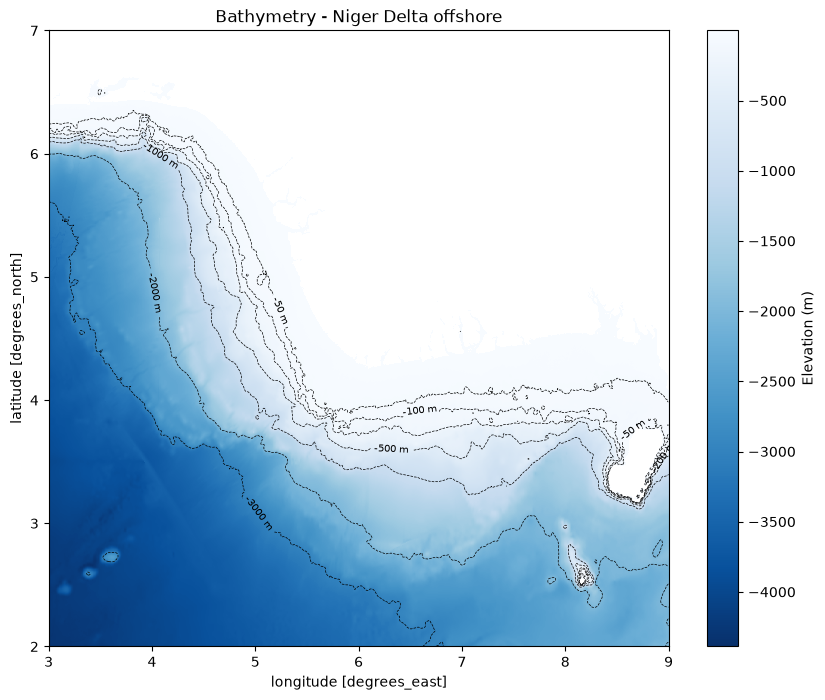

In [1]:
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset("gebco_2026_n7.0_s2.0_w3.0_e9.0.nc")
z = ds["elevation"]
sea = z.where(z < 0)

fig, ax = plt.subplots(figsize=(10, 8))
sea.plot(ax=ax, cmap="Blues_r", cbar_kwargs={"label": "Elevation (m)"})
cs = sea.plot.contour(ax=ax, levels=[-3000, -2000, -1000, -500, -200, -100, -50],
                      colors="black", linewidths=0.5)
ax.clabel(cs, fmt="%d m", fontsize=7)
ax.set_title("Bathymetry - Niger Delta offshore")
plt.savefig("niger_delta_bathymetry.png", dpi=200)
plt.show()

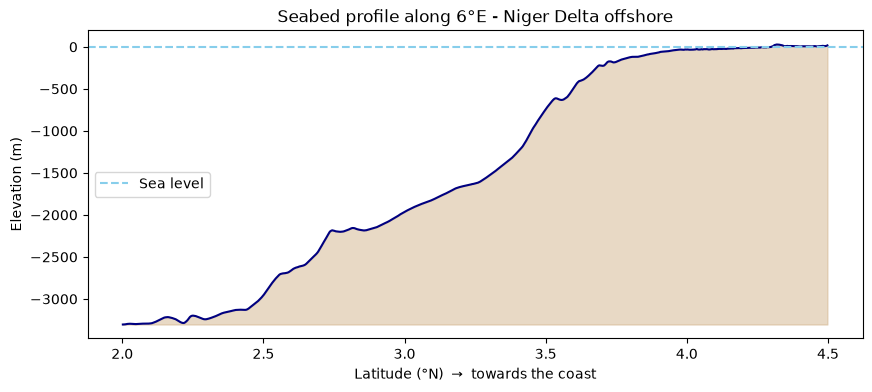

In [2]:
import matplotlib.pyplot as plt

profile = z.sel(lon=6.0, method="nearest").sel(lat=slice(2, 4.5))

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, color="navy")
ax.fill_between(profile.lat, profile, profile.min(), color="tan", alpha=0.5)
ax.axhline(0, color="skyblue", linestyle="--", label="Sea level")
ax.set_title("Seabed profile along 6°E - Niger Delta offshore")
ax.set_xlabel("Latitude (°N)  →  towards the coast")
ax.set_ylabel("Elevation (m)")
ax.legend()
plt.savefig("seabed_profile.png", dpi=200)
plt.show()